In [3]:

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

# Display all columns
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")


Libraries imported successfully!


In [5]:

from pathlib import Path

BASE_DIR = Path.cwd().parent

file_path = BASE_DIR / "data" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [7]:

# Display first five records
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
df.shape

(7043, 21)

In [9]:
df.columns.tolist()


['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [11]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [12]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [13]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [14]:
# Count duplicate rows
print("Duplicate records:", df.duplicated().sum())

# Check duplicate customer IDs
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

Duplicate records: 0
Duplicate customer IDs: 0


In [15]:
# Statistical summary of numerical columns
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


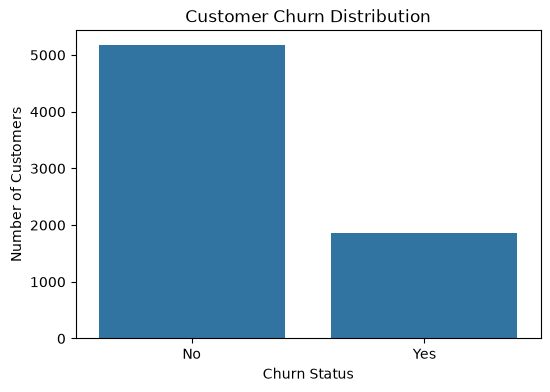

In [16]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

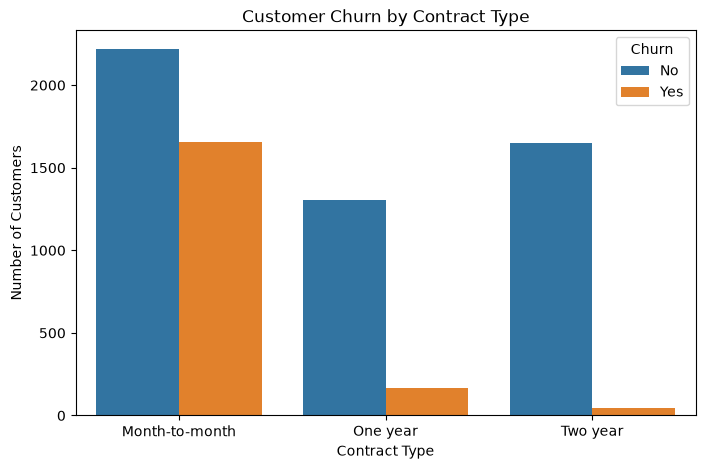

In [17]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

In [18]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn)

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


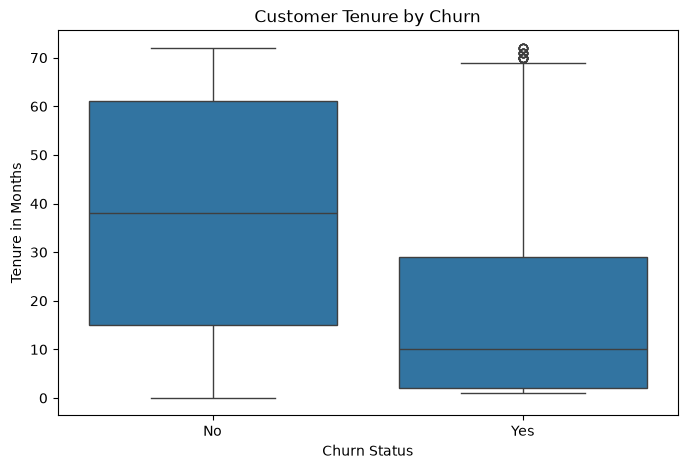

In [19]:

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Customer Tenure by Churn")
plt.xlabel("Churn Status")
plt.ylabel("Tenure in Months")

plt.show()


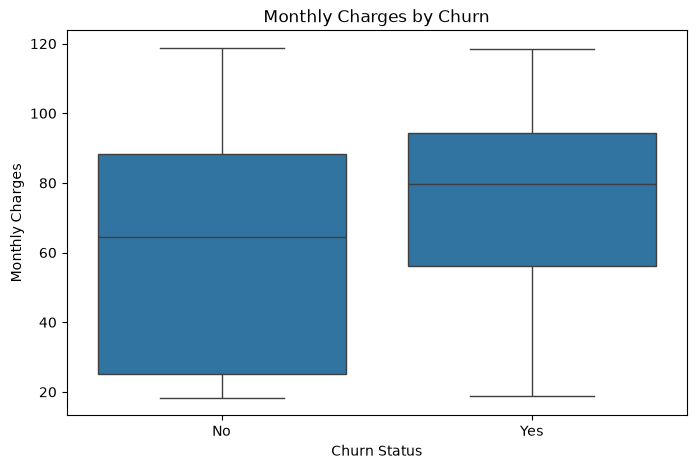

In [20]:

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges by Churn")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")

plt.show()


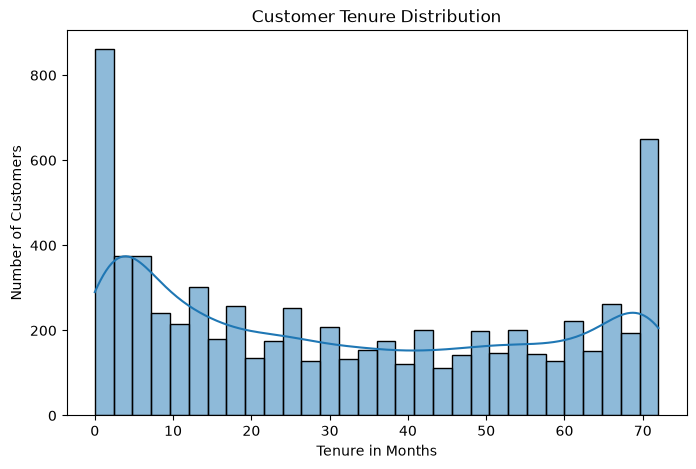

In [21]:

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="tenure", bins=30, kde=True)

plt.title("Customer Tenure Distribution")
plt.xlabel("Tenure in Months")
plt.ylabel("Number of Customers")

plt.show()


In [22]:

internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(internet_churn)


Churn                   No        Yes
InternetService                      
DSL              81.040892  18.959108
Fiber optic      58.107235  41.892765
No               92.595020   7.404980


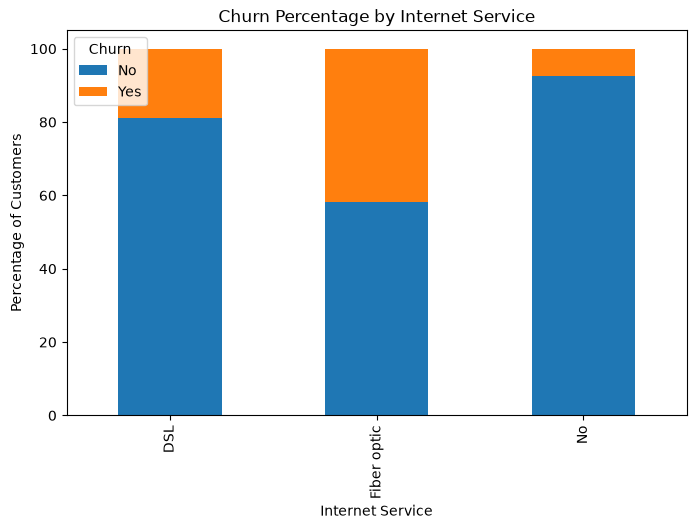

In [23]:

internet_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Churn Percentage by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")

plt.show()


In [24]:

# Create a copy for preprocessing
data = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", data.shape)


Original dataset shape: (7043, 21)
Working dataset shape: (7043, 21)


In [25]:

# Remove customerID column
data = data.drop("customerID", axis=1)

print("Shape after removing customerID:", data.shape)
print(data.head())


Shape after removing customerID: (7043, 20)
   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No          No              No  Month-

In [26]:

print("Before conversion:")
print(data["TotalCharges"].dtype)


Before conversion:
str


In [27]:

# Convert blank spaces into missing values
data["TotalCharges"] = data["TotalCharges"].replace(" ", np.nan)

# Convert TotalCharges into numerical values
data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"],
    errors="coerce"
)

print("After conversion:")
print(data["TotalCharges"].dtype)


After conversion:
float64


In [28]:

print(data.isnull().sum())


gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [29]:

missing_total_charges = data[data["TotalCharges"].isnull()]

print(missing_total_charges[["tenure", "MonthlyCharges", "TotalCharges"]])


      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN
3331       0           19.85           NaN
3826       0           25.35           NaN
4380       0           20.00           NaN
5218       0           19.70           NaN
6670       0           73.35           NaN
6754       0           61.90           NaN


In [30]:

# Fill missing TotalCharges with 0
data["TotalCharges"] = data["TotalCharges"].fillna(0)

# Check missing values again
print("Missing values after cleaning:")
print(data.isnull().sum().sum())


Missing values after cleaning:
0


In [31]:

# Convert Churn into numerical values
data["Churn"] = data["Churn"].map({
    "No": 0,
    "Yes": 1
})

print(data["Churn"].value_counts())
print("\nChurn data type:")
print(data["Churn"].dtype)


Churn
0    5174
1    1869
Name: count, dtype: int64

Churn data type:
int64


In [32]:

print("Dataset shape:", data.shape)

print("\nMissing values:")
print(data.isnull().sum().sum())

print("\nData types:")
print(data.dtypes)

print("\nFirst five records:")
print(data.head())


Dataset shape: (7043, 20)

Missing values:
0

Data types:
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object

First five records:
   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Fema

In [33]:

# Identify categorical columns
categorical_columns = data.select_dtypes(
    include=["object"]
).columns.tolist()

print("Categorical columns:")
print(categorical_columns)


Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\91809\AppData\Local\Temp\ipykernel_12096\2835239150.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = data.select_dtypes(


In [34]:

# Convert categorical columns into numerical columns
data_encoded = pd.get_dummies(
    data,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

print("Shape after encoding:", data_encoded.shape)
print(data_encoded.head())


Shape after encoding: (7043, 31)
   SeniorCitizen  tenure  MonthlyCharges  TotalCharges  Churn  gender_Male  \
0              0       1           29.85         29.85      0            0   
1              0      34           56.95       1889.50      0            1   
2              0       2           53.85        108.15      1            1   
3              0      45           42.30       1840.75      0            1   
4              0       2           70.70        151.65      1            0   

   Partner_Yes  Dependents_Yes  PhoneService_Yes  \
0            1               0                 0   
1            0               0                 1   
2            0               0                 1   
3            0               0                 0   
4            0               0                 1   

   MultipleLines_No phone service  MultipleLines_Yes  \
0                               1                  0   
1                               0                  0   
2                

In [35]:

# Input features
X = data_encoded.drop("Churn", axis=1)

# Target column
y = data_encoded["Churn"]

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (7043, 30)
y shape: (7043,)


In [36]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (5634, 30)
Testing features: (1409, 30)
Training target: (5634,)
Testing target: (1409,)


In [37]:

from sklearn.preprocessing import StandardScaler

# Numerical columns to scale
numerical_columns = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

scaler = StandardScaler()

# Fit scaler only on training data
X_train[numerical_columns] = scaler.fit_transform(
    X_train[numerical_columns]
)

# Transform test data using training scaler
X_test[numerical_columns] = scaler.transform(
    X_test[numerical_columns]
)

print("Scaling completed!")


Scaling completed!


In [41]:

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nChurn percentage in training data:")
print(y_train.value_counts(normalize=True) * 100)

print("\nChurn percentage in testing data:")
print(y_test.value_counts(normalize=True) * 100)


Training data: (5634, 30)
Testing data: (1409, 30)

Churn percentage in training data:
Churn
0    73.464679
1    26.535321
Name: proportion, dtype: float64

Churn percentage in testing data:
Churn
0    73.456352
1    26.543648
Name: proportion, dtype: float64


In [42]:

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

print("Machine Learning algorithms imported successfully!")


Machine Learning algorithms imported successfully!


In [43]:

# Create Logistic Regression model
log_model = LogisticRegression(max_iter=1000)

# Train the model
log_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [44]:

# Predict churn using test data
log_predictions = log_model.predict(X_test)

print("First 20 actual values:")
print(y_test.head(20).values)

print("\nFirst 20 predicted values:")
print(log_predictions[:20])


First 20 actual values:
[0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0]

First 20 predicted values:
[0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 0]


In [45]:

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [46]:

# Predict churn using Random Forest
rf_predictions = rf_model.predict(X_test)

print("First 20 actual values:")
print(y_test.head(20).values)

print("\nFirst 20 Random Forest predictions:")
print(rf_predictions[:20])


First 20 actual values:
[0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0]

First 20 Random Forest predictions:
[0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0]


In [47]:

print("Logistic Regression predictions:")
print(pd.Series(log_predictions).value_counts())

print("\nRandom Forest predictions:")
print(pd.Series(rf_predictions).value_counts())


Logistic Regression predictions:
0    1091
1     318
Name: count, dtype: int64

Random Forest predictions:
0    1110
1     299
Name: count, dtype: int64


In [48]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("Evaluation metrics imported successfully!")


Evaluation metrics imported successfully!


In [49]:

log_accuracy = accuracy_score(y_test, log_predictions)

rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Logistic Regression Accuracy:", log_accuracy)
print("Random Forest Accuracy:", rf_accuracy)

print("\nAccuracy in percentage:")
print("Logistic Regression:", log_accuracy * 100)
print("Random Forest:", rf_accuracy * 100)


Logistic Regression Accuracy: 0.8069552874378992
Random Forest Accuracy: 0.7849538679914834

Accuracy in percentage:
Logistic Regression: 80.69552874378992
Random Forest: 78.49538679914833


In [50]:

log_precision = precision_score(y_test, log_predictions)
rf_precision = precision_score(y_test, rf_predictions)

print("Logistic Regression Precision:", log_precision)
print("Random Forest Precision:", rf_precision)


Logistic Regression Precision: 0.660377358490566
Random Forest Precision: 0.6187290969899666


In [51]:

log_recall = recall_score(y_test, log_predictions)
rf_recall = recall_score(y_test, rf_predictions)

print("Logistic Regression Recall:", log_recall)
print("Random Forest Recall:", rf_recall)


Logistic Regression Recall: 0.5614973262032086
Random Forest Recall: 0.4946524064171123


In [52]:

log_f1 = f1_score(y_test, log_predictions)
rf_f1 = f1_score(y_test, rf_predictions)

print("Logistic Regression F1-score:", log_f1)
print("Random Forest F1-score:", rf_f1)


Logistic Regression F1-score: 0.6069364161849711
Random Forest F1-score: 0.549777117384844


In [53]:

# Logistic Regression confusion matrix
log_cm = confusion_matrix(y_test, log_predictions)

print("Logistic Regression:")
print(log_cm)

# Random Forest confusion matrix
rf_cm = confusion_matrix(y_test, rf_predictions)

print("\nRandom Forest:")
print(rf_cm)


Logistic Regression:
[[927 108]
 [164 210]]

Random Forest:
[[921 114]
 [189 185]]


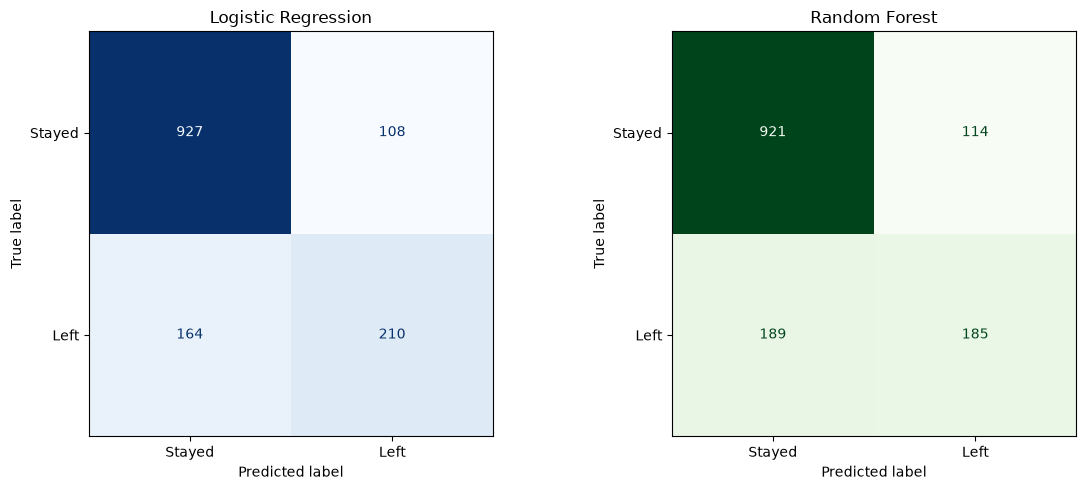

In [54]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    log_cm,
    display_labels=["Stayed", "Left"]
).plot(ax=axes[0], cmap="Blues", colorbar=False)

axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay(
    rf_cm,
    display_labels=["Stayed", "Left"]
).plot(ax=axes[1], cmap="Greens", colorbar=False)

axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()


In [55]:

print("LOGISTIC REGRESSION REPORT")
print(classification_report(y_test, log_predictions))

print("\nRANDOM FOREST REPORT")
print(classification_report(y_test, rf_predictions))


LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1035
           1       0.66      0.56      0.61       374

    accuracy                           0.81      1409
   macro avg       0.76      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


RANDOM FOREST REPORT
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.62      0.49      0.55       374

    accuracy                           0.78      1409
   macro avg       0.72      0.69      0.70      1409
weighted avg       0.77      0.78      0.78      1409



In [56]:

# Get prediction probabilities for churn class
log_probabilities = log_model.predict_proba(X_test)[:, 1]

rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

# Calculate ROC-AUC
log_auc = roc_auc_score(y_test, log_probabilities)

rf_auc = roc_auc_score(y_test, rf_probabilities)

print("Logistic Regression ROC-AUC:", log_auc)
print("Random Forest ROC-AUC:", rf_auc)


Logistic Regression ROC-AUC: 0.8421710713270816
Random Forest ROC-AUC: 0.8248417680642744


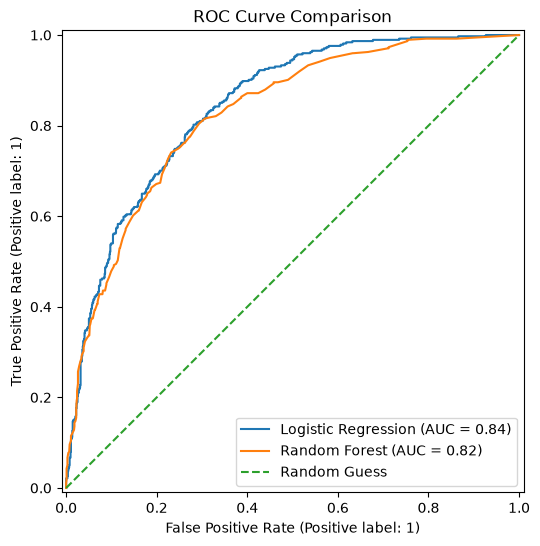

In [57]:

fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    log_probabilities,
    name="Logistic Regression",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test,
    rf_probabilities,
    name="Random Forest",
    ax=ax
)

ax.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")

plt.title("ROC Curve Comparison")
plt.legend()
plt.show()


In [58]:

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [log_accuracy, rf_accuracy],
    "Precision": [log_precision, rf_precision],
    "Recall": [log_recall, rf_recall],
    "F1-Score": [log_f1, rf_f1],
    "ROC-AUC": [log_auc, rf_auc]
})

print(comparison.round(4))


                 Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
0  Logistic Regression     0.807     0.6604  0.5615    0.6069   0.8422
1        Random Forest     0.785     0.6187  0.4947    0.5498   0.8248


In [59]:
balanced_log_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

balanced_log_model.fit(X_train, y_train)

balanced_predictions = balanced_log_model.predict(X_test)

In [60]:
balanced_accuracy = accuracy_score(y_test, balanced_predictions)

balanced_precision = precision_score(y_test, balanced_predictions)

balanced_recall = recall_score(y_test, balanced_predictions)

balanced_f1 = f1_score(y_test, balanced_predictions)

balanced_probabilities = balanced_log_model.predict_proba(X_test)[:, 1]

balanced_auc = roc_auc_score(y_test, balanced_probabilities)

print("Balanced Logistic Regression Results")
print("-------------------------------------")
print("Accuracy:", round(balanced_accuracy, 4))
print("Precision:", round(balanced_precision, 4))
print("Recall:", round(balanced_recall, 4))
print("F1-Score:", round(balanced_f1, 4))
print("ROC-AUC:", round(balanced_auc, 4))

Balanced Logistic Regression Results
-------------------------------------
Accuracy: 0.7388
Precision: 0.5052
Recall: 0.7834
F1-Score: 0.6143
ROC-AUC: 0.8417


In [61]:
model_comparison = pd.DataFrame({
    "Model": [
        "Original Logistic Regression",
        "Balanced Logistic Regression"
    ],
    "Accuracy": [
        log_accuracy,
        balanced_accuracy
    ],
    "Precision": [
        log_precision,
        balanced_precision
    ],
    "Recall": [
        log_recall,
        balanced_recall
    ],
    "F1-Score": [
        log_f1,
        balanced_f1
    ],
    "ROC-AUC": [
        log_auc,
        balanced_auc
    ]
})

print(model_comparison.round(4))

                          Model  Accuracy  Precision  Recall  F1-Score  \
0  Original Logistic Regression    0.8070     0.6604  0.5615    0.6069   
1  Balanced Logistic Regression    0.7388     0.5052  0.7834    0.6143   

   ROC-AUC  
0   0.8422  
1   0.8417  


In [62]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["liblinear", "lbfgs"],
    "class_weight": ["balanced"]
}

grid_search = GridSearchCV(
    LogisticRegression(max_iter=2000),
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross Validation F1:", grid_search.best_score_)

Best Parameters: {'C': 0.1, 'class_weight': 'balanced', 'solver': 'lbfgs'}
Best Cross Validation F1: 0.6332791312211126


In [63]:
best_model = grid_search.best_estimator_

best_predictions = best_model.predict(X_test)

best_probabilities = best_model.predict_proba(X_test)[:, 1]

In [64]:
best_accuracy = accuracy_score(y_test, best_predictions)

best_precision = precision_score(y_test, best_predictions)

best_recall = recall_score(y_test, best_predictions)

best_f1 = f1_score(y_test, best_predictions)

best_auc = roc_auc_score(y_test, best_probabilities)

print("Tuned Logistic Regression Results")
print("---------------------------------")
print("Accuracy:", round(best_accuracy, 4))
print("Precision:", round(best_precision, 4))
print("Recall:", round(best_recall, 4))
print("F1-Score:", round(best_f1, 4))
print("ROC-AUC:", round(best_auc, 4))

Tuned Logistic Regression Results
---------------------------------
Accuracy: 0.7424
Precision: 0.5096
Recall: 0.7834
F1-Score: 0.6175
ROC-AUC: 0.8414


In [65]:
final_comparison = pd.DataFrame({
    "Model": [
        "Original Logistic Regression",
        "Balanced Logistic Regression",
        "Tuned Logistic Regression"
    ],
    "Accuracy": [
        log_accuracy,
        balanced_accuracy,
        best_accuracy
    ],
    "Precision": [
        log_precision,
        balanced_precision,
        best_precision
    ],
    "Recall": [
        log_recall,
        balanced_recall,
        best_recall
    ],
    "F1-Score": [
        log_f1,
        balanced_f1,
        best_f1
    ],
    "ROC-AUC": [
        log_auc,
        balanced_auc,
        best_auc
    ]
})

print(final_comparison.round(4))

                          Model  Accuracy  Precision  Recall  F1-Score  \
0  Original Logistic Regression    0.8070     0.6604  0.5615    0.6069   
1  Balanced Logistic Regression    0.7388     0.5052  0.7834    0.6143   
2     Tuned Logistic Regression    0.7424     0.5096  0.7834    0.6175   

   ROC-AUC  
0   0.8422  
1   0.8417  
2   0.8414  


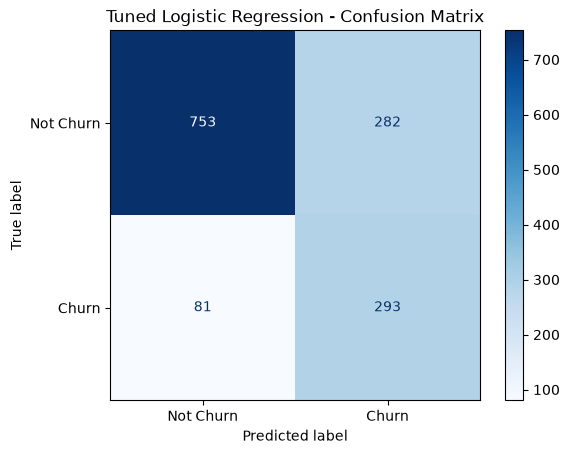

In [66]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    display_labels=["Not Churn", "Churn"],
    cmap="Blues"
)

plt.title("Tuned Logistic Regression - Confusion Matrix")
plt.show()

In [67]:
print(classification_report(
    y_test,
    best_predictions,
    target_names=["Not Churn", "Churn"]
))

              precision    recall  f1-score   support

   Not Churn       0.90      0.73      0.81      1035
       Churn       0.51      0.78      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409



In [68]:
prediction_results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": best_predictions
})

prediction_results["Actual"] = prediction_results["Actual"].map({
    0: "Not Churn",
    1: "Churn"
})

prediction_results["Predicted"] = prediction_results["Predicted"].map({
    0: "Not Churn",
    1: "Churn"
})

print(prediction_results.head(10))

      Actual  Predicted
0  Not Churn  Not Churn
1  Not Churn      Churn
2  Not Churn  Not Churn
3  Not Churn      Churn
4  Not Churn  Not Churn
5  Not Churn      Churn
6  Not Churn      Churn
7  Not Churn  Not Churn
8  Not Churn  Not Churn
9      Churn      Churn


In [69]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, best_predictions)

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

True Negatives: 753
False Positives: 282
False Negatives: 81
True Positives: 293


In [70]:
import joblib
from pathlib import Path

In [71]:
BASE_DIR = Path.cwd().parent
model_dir = BASE_DIR / "models"

model_dir.mkdir(exist_ok=True)

model_package = {
    "model": best_model,
    "scaler": scaler,
    "feature_columns": X.columns.tolist(),
    "numerical_columns": numerical_columns
}

joblib.dump(
    model_package,
    model_dir / "churn_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!
